# No-Churn Telecom Customer Churn Prediction Using Machine Learning

### Client Project: No-Churn Telecom (PRCL-0017)

**Submitted By:**
Yuvasree M

**Project Code:**
PRCL-0017

**Domain:**
Telecommunications

**Project Type:**
Client Project

**Organization:**
DataMites

**Course:**
Certified Data Scientist (CDS)


# Business Problem

Customer churn is one of the biggest challenges faced by telecommunication companies. Acquiring a new customer is significantly more expensive than retaining an existing one. Therefore, identifying customers who are likely to discontinue telecom services is crucial for improving customer retention and maximizing business profitability.

No-Churn Telecom aims to leverage Machine Learning techniques to identify customers who are at high risk of churn so that proactive retention strategies can be implemented.

# Business Objective

The primary objective of this project is to build a Machine Learning model capable of predicting customer churn accurately. The model will help the business identify high-risk customers and enable targeted retention campaigns to reduce customer attrition and improve overall customer satisfaction.


# Project Objectives

- Understand customer behavior using historical telecom data.
- Perform comprehensive Exploratory Data Analysis (EDA).
- Clean and preprocess the dataset.
- Build multiple Machine Learning classification models.
- Compare model performance using evaluation metrics.
- Select the best-performing model.
- Generate actionable business recommendations to reduce customer churn.

# Project Workflow

1. Business Understanding
2. Data Collection
3. Data Understanding
4. Data Cleaning
5. Exploratory Data Analysis (EDA)
6. Feature Engineering
7. Data Preprocessing
8. Model Building
9. Hyperparameter Tuning
10. Model Evaluation
11. Model Comparison
12. Business Recommendations
13. Future Scope
14. Conclusion

## IMPORTING LIBRARIES

In [4]:
# Import Required Libraries
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymysql
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [5]:
!pip install pymysql

## CONNECT TO MYSQL DATABASE

In [6]:
# Connect to MySQL Database
import pymysql
connection = pymysql.connect(
    host="18.136.157.135",
    user="dm_team3",
    password="DM!$!Team!27@9!20&",
    database="project_telecom"
)
print(" Database Connected Successfully!")

 Database Connected Successfully!


## LOAD THE DATASET

In [7]:
# Load Dataset from SQL
query = "SELECT * FROM telecom_churn_data"
df = pd.read_sql(query, connection)
print(" Dataset Loaded Successfully!")

 Dataset Loaded Successfully!


## BASIC CHECK

In [8]:
df.head()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [9]:
print("Dataset Shape:", df.shape)

Dataset Shape: (243553, 14)


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   customer_id           243553 non-null  int64 
 1   telecom_partner       243553 non-null  object
 2   gender                243553 non-null  object
 3   age                   243553 non-null  int64 
 4   state                 243553 non-null  object
 5   city                  243553 non-null  object
 6   pincode               243553 non-null  int64 
 7   date_of_registration  243553 non-null  object
 8   num_dependents        243553 non-null  int64 
 9   estimated_salary      243553 non-null  int64 
 10  calls_made            243553 non-null  int64 
 11  sms_sent              243553 non-null  int64 
 12  data_used             243553 non-null  int64 
 13  churn                 243553 non-null  int64 
dtypes: int64(9), object(5)
memory usage: 26.0+ MB


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,243553.0,121777.000000,70307.839393,1.0,60889.0,121777.0,182665.0,243553.0
age,243553.0,46.077609,16.444029,18.0,32.0,46.0,60.0,74.0
pincode,243553.0,549501.270541,259808.860574,100006.0,324586.0,548112.0,774994.0,999987.0
num_dependents,243553.0,1.997500,1.414941,0.0,1.0,2.0,3.0,4.0
estimated_salary,243553.0,85021.137839,37508.963233,20000.0,52585.0,84990.0,117488.0,149999.0
calls_made,243553.0,49.010548,29.453556,-10.0,24.0,49.0,74.0,108.0
sms_sent,243553.0,23.945404,14.733575,-5.0,11.0,24.0,36.0,53.0
data_used,243553.0,4993.186025,2942.019547,-987.0,2490.0,4987.0,7493.0,10991.0
churn,243553.0,0.200478,0.400359,0.0,0.0,0.0,0.0,1.0


In [12]:
df.tail()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
243548,243549,Airtel,F,28,Mizoram,Kolkata,110295,2023-05-03,3,130580,28,9,4102,0
243549,243550,Reliance Jio,F,52,Assam,Kolkata,713481,2023-05-03,0,82393,80,45,7521,0
243550,243551,Reliance Jio,M,59,Tripura,Kolkata,520218,2023-05-03,4,51298,26,4,6547,0
243551,243552,BSNL,M,49,Madhya Pradesh,Kolkata,387744,2023-05-03,2,83981,80,15,1125,0
243552,243553,BSNL,F,37,Telangana,Hyderabad,139086,2023-05-04,0,144297,61,7,3384,0


In [13]:
df.isnull().sum()

customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64

In [14]:
# Duplicate Records
print("Duplicate Records :", df.duplicated().sum())

Duplicate Records : 0


## EDA

# Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the characteristics of the dataset, identify patterns, detect anomalies, and derive meaningful business insights before building Machine Learning models.

EDA is divided into:

- Univariate Analysis
- Bivariate Analysis
- Multivariate Analysis

## UNIVARIATE ANALYSIS

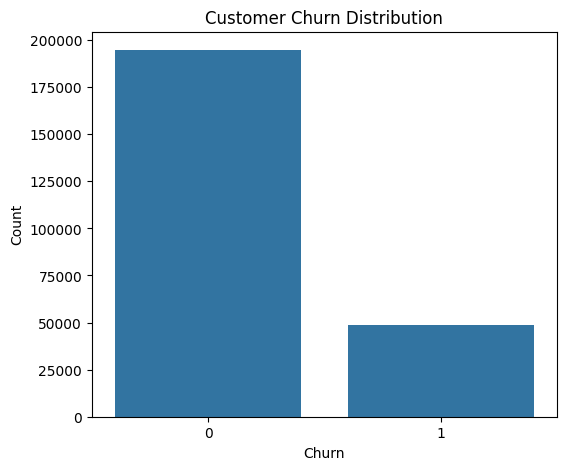

In [15]:
## 1. TARGET VARIABLE ANALYSIS
plt.figure(figsize=(6,5))
sns.countplot(x='churn', data=df)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.show()

### Observation
- Majority of customers did not churn.
- Approximately 20% of customers have churned.
- The dataset is imbalanced.
- SMOTE or class balancing techniques may be required during model building.

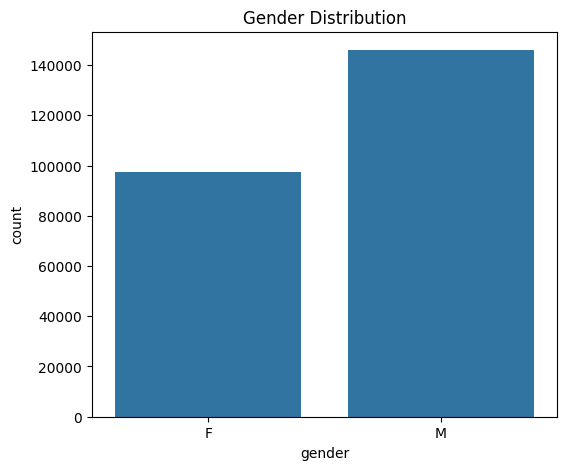

In [16]:
## 2. GENDER DISTRIBUTION
plt.figure(figsize=(6,5))
sns.countplot(x='gender', data=df)
plt.title("Gender Distribution")
plt.show()

### Observation

- This visualization shows the distribution of male and female customers.
- It helps determine whether the dataset has balanced gender representation.

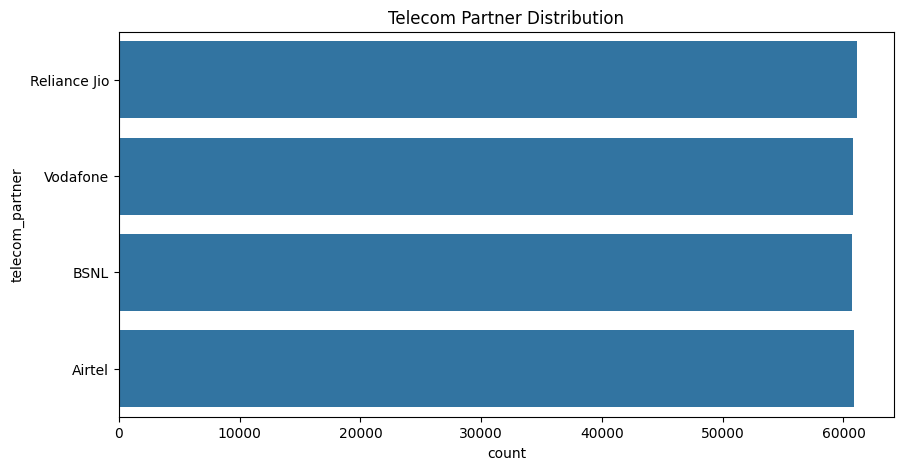

In [17]:
## 3. TELECOM PARTNER
plt.figure(figsize=(10,5))
sns.countplot(y='telecom_partner', data=df)
plt.title("Telecom Partner Distribution")
plt.show()

### Observation
- Different telecom partners have different customer bases.
- Companies with larger customer bases may naturally experience more churn.

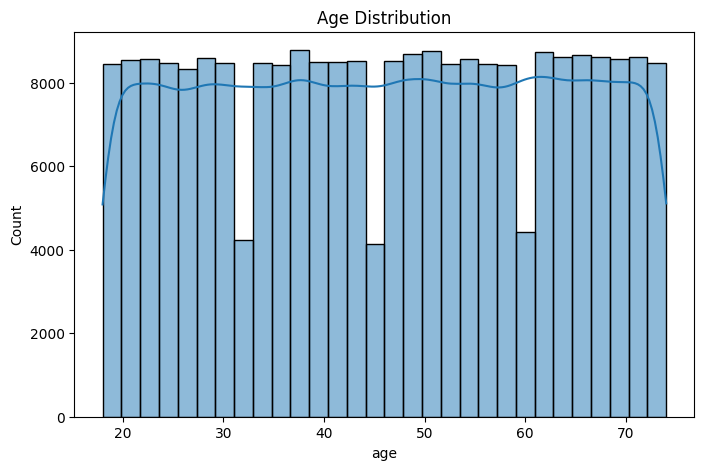

In [18]:
## 4. AGE DISTRIBUTION
plt.figure(figsize=(8,5))
sns.histplot(df['age'], bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

### Observation

- Customer ages range approximately from **18 to 75 years**.
- The age distribution is fairly uniform across different age groups.
- There is no significant skewness toward younger or older customers.
- Customers from all age groups are represented, which helps build a generalized churn prediction model.
- Further analysis (Age vs Churn) will help determine whether specific age groups are more likely to churn.

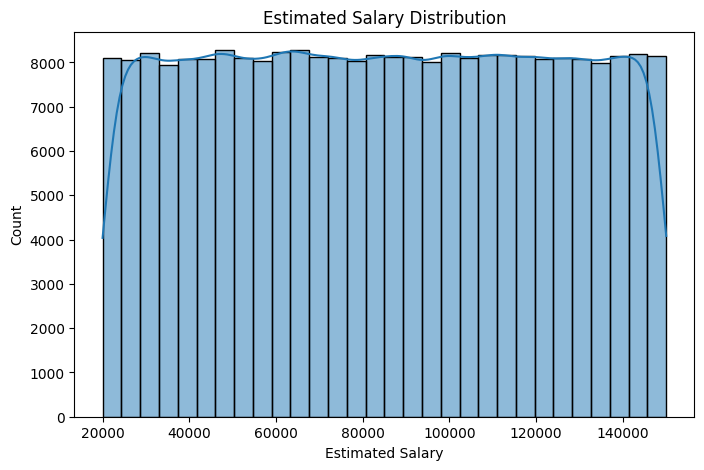

In [19]:
# 5. Estimated Salary Distribution

plt.figure(figsize=(8,5))

sns.histplot(df['estimated_salary'], bins=30, kde=True)

plt.title("Estimated Salary Distribution")
plt.xlabel("Estimated Salary")
plt.ylabel("Count")

plt.show()

### Observation

- Estimated salaries range approximately from **20,000 to 150,000**.
- The salary distribution appears to be fairly uniform, with no significant concentration in a particular income range.
- There is no noticeable skewness or extreme salary outliers.
- Customers belong to diverse income groups, making salary an important feature for further churn analysis.
- In the next stage (Salary vs Churn), we will analyze whether customers with specific salary levels are more likely to leave the telecom service.

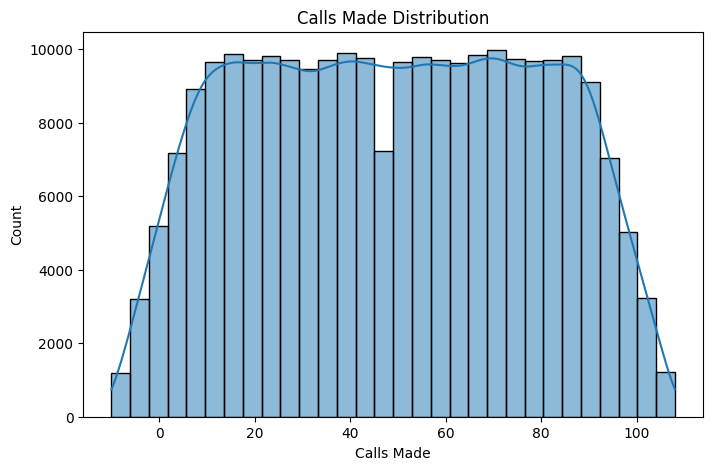

In [20]:
# 6. Calls Made Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['calls_made'], bins=30, kde=True)
plt.title("Calls Made Distribution")
plt.xlabel("Calls Made")
plt.ylabel("Count")
plt.show()

### Observation

- Customers made a wide range of calls, indicating diverse calling behaviors.
- The distribution is relatively balanced, with no significant skewness.
- Most customers exhibit moderate to high call activity.
- No extreme outliers are visible in the distribution.
- Further analysis (Calls Made vs Churn) will determine whether call frequency influences customer churn.

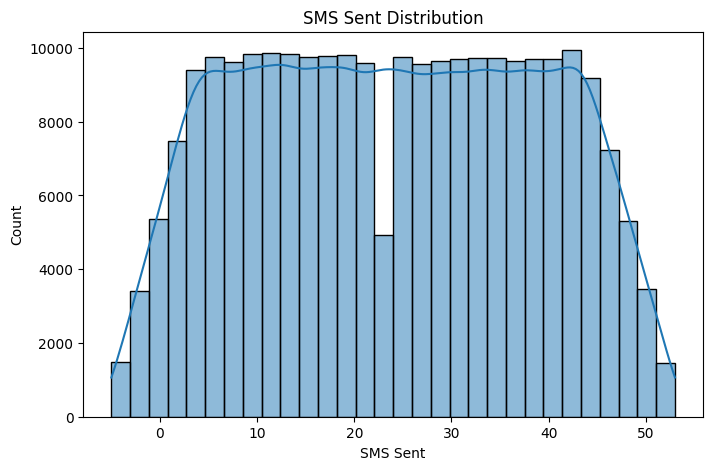

In [21]:
# 7. SMS Sent Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['sms_sent'], bins=30, kde=True)
plt.title("SMS Sent Distribution")
plt.xlabel("SMS Sent")
plt.ylabel("Count")
plt.show()

### Observation

- Customers exhibit a wide range of SMS usage patterns.
- The distribution is fairly balanced, indicating that customers send varying numbers of SMS messages.
- No significant skewness or extreme outliers are observed.
- SMS usage alone does not indicate churn and requires further analysis with the target variable.
- The relationship between SMS usage and customer churn will be examined during bivariate analysis.

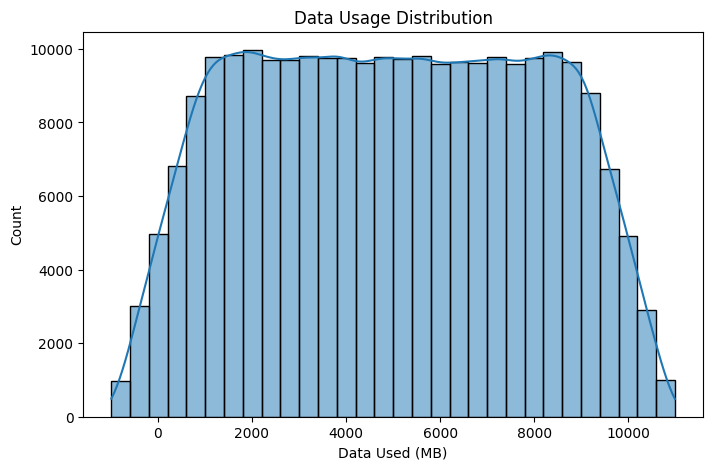

In [22]:
# 8. Data Used Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['data_used'], bins=30, kde=True)
plt.title("Data Usage Distribution")
plt.xlabel("Data Used (MB)")
plt.ylabel("Count")
plt.show()

## BIVARIATE ANALYSIS

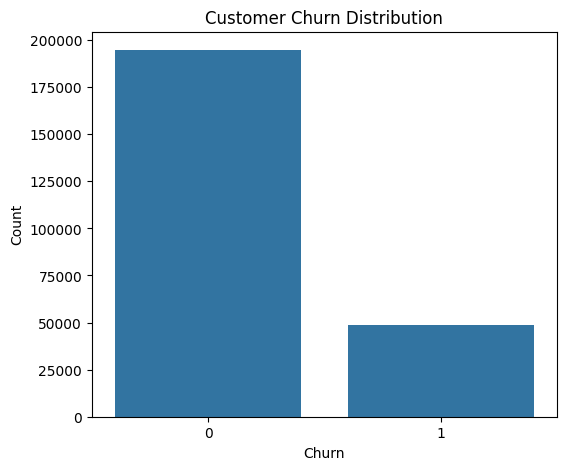

In [23]:
## 1. CHURN DISTRIBUTION
plt.figure(figsize=(6,5))
sns.countplot(x='churn', data=df)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.show()

### Insight

- The target variable (Churn) is highly imbalanced.
- Approximately **80%** of customers did not churn (0), while **20%** of customers churned (1).
- This indicates a class imbalance problem, which can negatively affect machine learning models by biasing predictions toward the majority class.
- Therefore, techniques such as **SMOTE (Synthetic Minority Oversampling Technique)** or class weighting will be considered during model building to improve prediction performance.

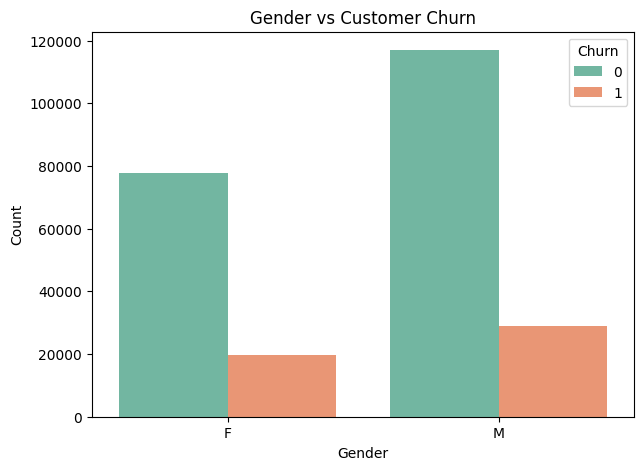

In [24]:
# Gender vs Churn
plt.figure(figsize=(7,5))
sns.countplot(
    x='gender',
    hue='churn',
    data=df,
    palette='Set2'
)
plt.title("Gender vs Customer Churn")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Churn")
plt.show()

### Insight

- Male customers have a higher number of churn cases (29,022) than female customers (19,805).
- However, this is primarily because the dataset contains more male customers than female customers.
- Both genders exhibit a similar churn pattern, suggesting that gender alone is not a strong predictor of customer churn.
- Additional features such as service usage, salary, and telecom partner are likely to have a greater influence on churn behavior.

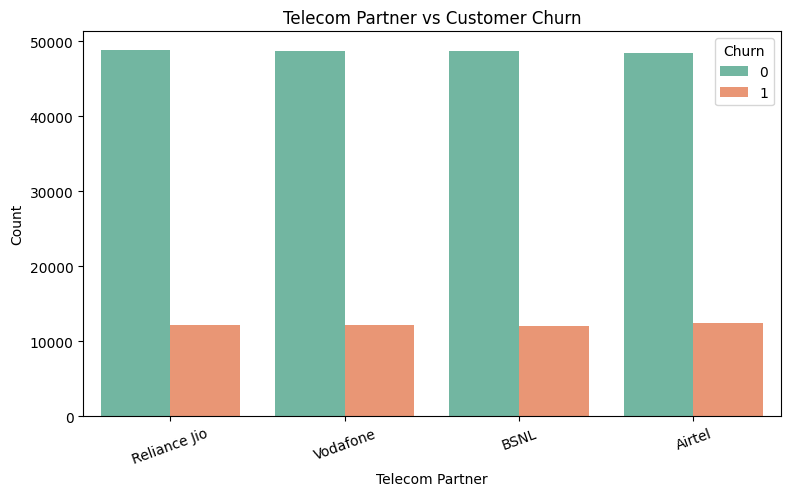

In [25]:
# Telecom Partner vs Churn
plt.figure(figsize=(9,5))
sns.countplot(
    x='telecom_partner',
    hue='churn',
    data=df,
    palette='Set2'
)
plt.title("Telecom Partner vs Customer Churn")
plt.xlabel("Telecom Partner")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.legend(title="Churn")
plt.show()

### Insight

- All four telecom partners have a nearly equal number of customers.
- Customer churn is distributed almost uniformly across Airtel, BSNL, Reliance Jio, and Vodafone.
- No telecom partner exhibits a significantly higher churn rate than the others.
- This suggests that the telecom partner alone is not a strong driver of customer churn.
- Other customer attributes such as age, service usage, estimated salary, and customer engagement should be analyzed to better understand churn behavior.

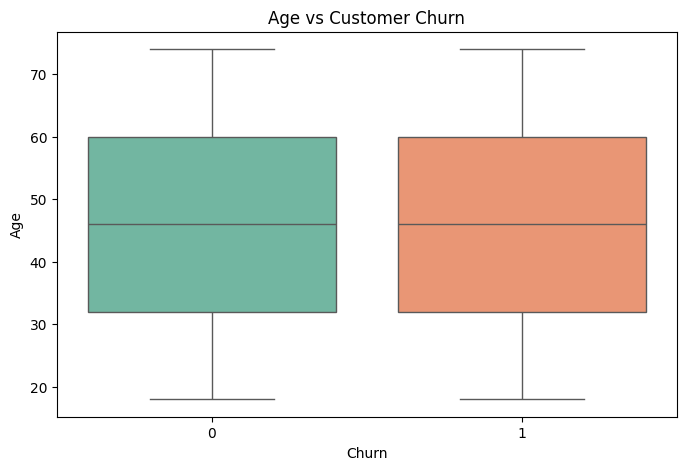

In [26]:
# Age vs Churn
plt.figure(figsize=(8,5))
sns.boxplot(
    x='churn',
    y='age',
    data=df,
    palette='Set2'
)
plt.title("Age vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Age")
plt.show()

### Insight

- The median age of customers is nearly the same for both churned and non-churned groups (approximately 46 years).
- The spread of ages (interquartile range) is also very similar across both groups.
- There are no significant differences in age distribution between customers who churned and those who remained.
- This indicates that age alone is not a strong predictor of customer churn.
- Churn is likely influenced more by customer behavior and service usage than by age.

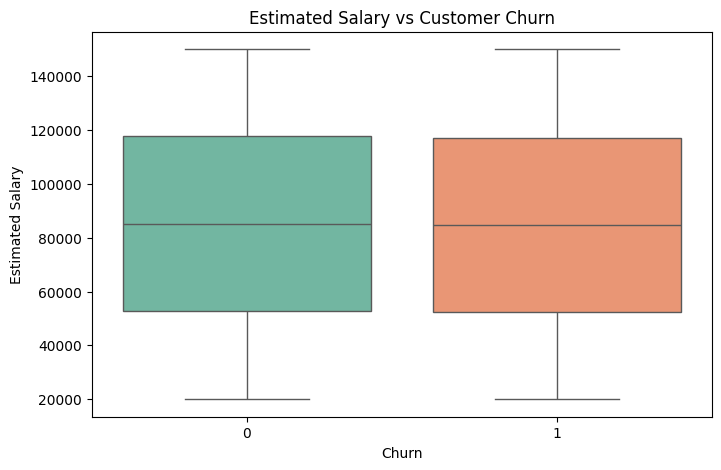

In [27]:
# Estimated Salary vs Churn
plt.figure(figsize=(8,5))
sns.boxplot(
    x='churn',
    y='estimated_salary',
    data=df,
    palette='Set2'
)
plt.title("Estimated Salary vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Estimated Salary")
plt.show()

### Insight

- The median estimated salary is nearly the same for both churned and non-churned customers (approximately $85,000).
- The spread of salary values is very similar across both groups.
- No noticeable difference exists in salary distribution between customers who churned and those who remained.
- This indicates that estimated salary alone does not significantly influence customer churn.
- Customer churn is more likely to be associated with service usage patterns and customer engagement than with income level.

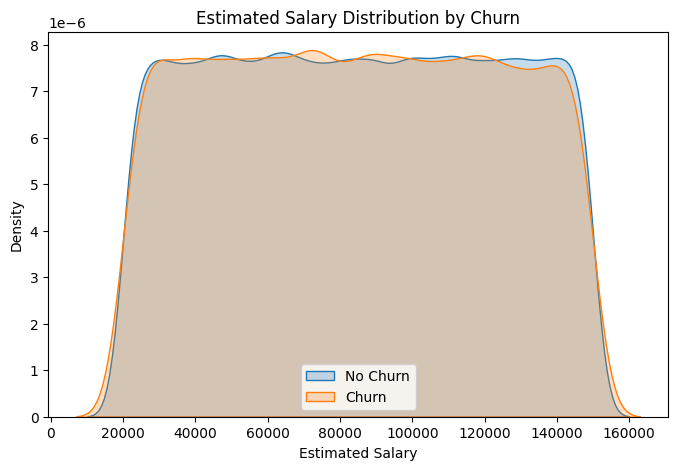

In [28]:
plt.figure(figsize=(8,5))

sns.kdeplot(
    data=df[df['churn']==0],
    x='estimated_salary',
    fill=True,
    label='No Churn'
)

sns.kdeplot(
    data=df[df['churn']==1],
    x='estimated_salary',
    fill=True,
    label='Churn'
)

plt.title("Estimated Salary Distribution by Churn")
plt.xlabel("Estimated Salary")
plt.legend()

plt.show()

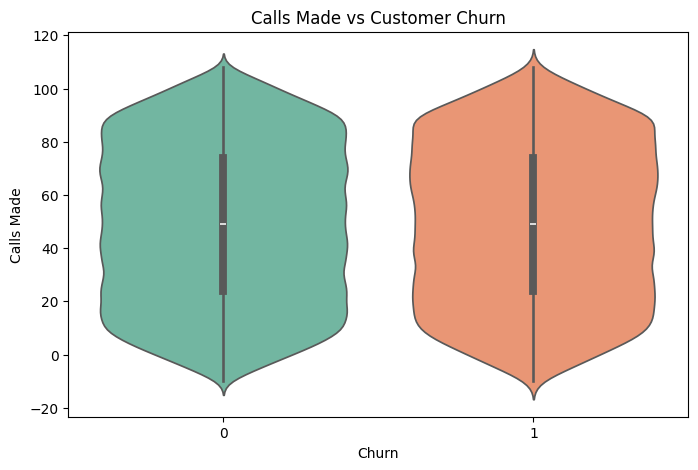

In [29]:
# Calls Made vs Churn
plt.figure(figsize=(8,5))
sns.violinplot(
    x='churn',
    y='calls_made',
    data=df,
    palette='Set2'
)
plt.title("Calls Made vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Calls Made")
plt.show()

### Insight

- The distribution of calls made is similar for churned and non-churned customers.
- Both customer groups show a wide range of call activity.
- There is no strong visual evidence that the number of calls made alone determines customer churn.
- Calls made may contribute to churn prediction when combined with other service usage features.

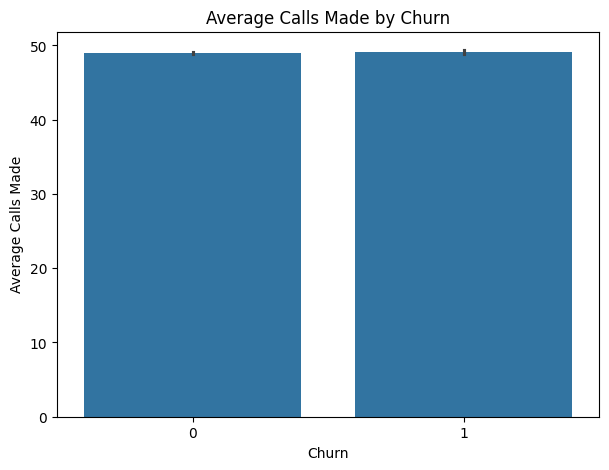

In [30]:
plt.figure(figsize=(7,5))
sns.barplot(
    x='churn',
    y='calls_made',
    data=df,
    estimator='mean'
)
plt.title("Average Calls Made by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Calls Made")
plt.show()

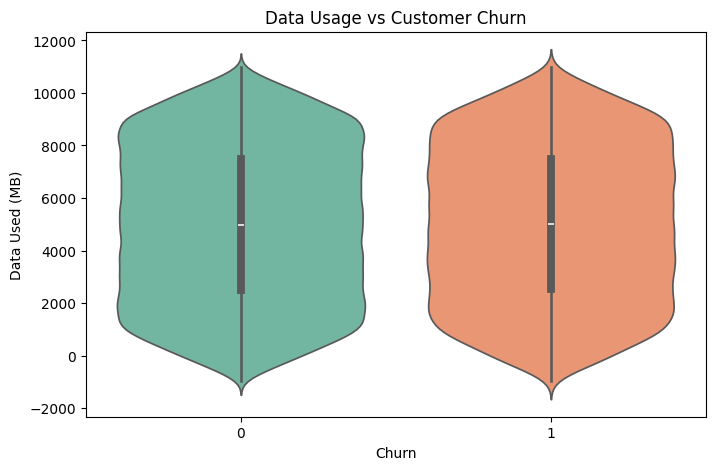

In [31]:
# Data Used vs Churn

plt.figure(figsize=(8,5))

sns.violinplot(
    x='churn',
    y='data_used',
    data=df,
    palette='Set2'
)

plt.title("Data Usage vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Data Used (MB)")

plt.show()

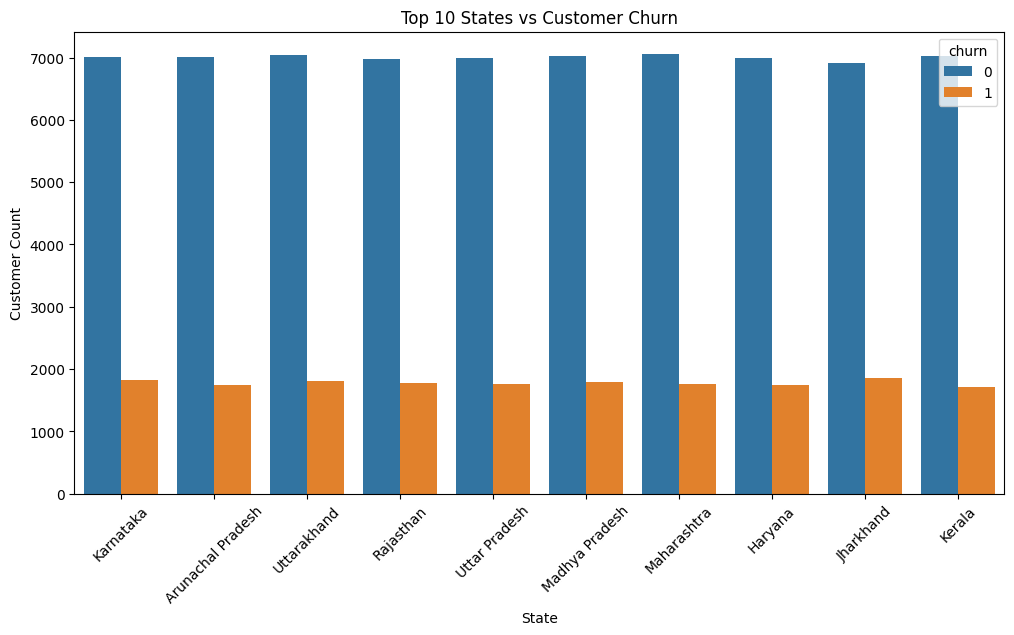

In [32]:
# State vs Churn (Top 10 States)

top_states = df['state'].value_counts().head(10).index

plt.figure(figsize=(12,6))

sns.countplot(
    data=df[df['state'].isin(top_states)],
    x='state',
    hue='churn'
)

plt.title("Top 10 States vs Customer Churn")
plt.xlabel("State")
plt.ylabel("Customer Count")
plt.xticks(rotation=45)

plt.show()

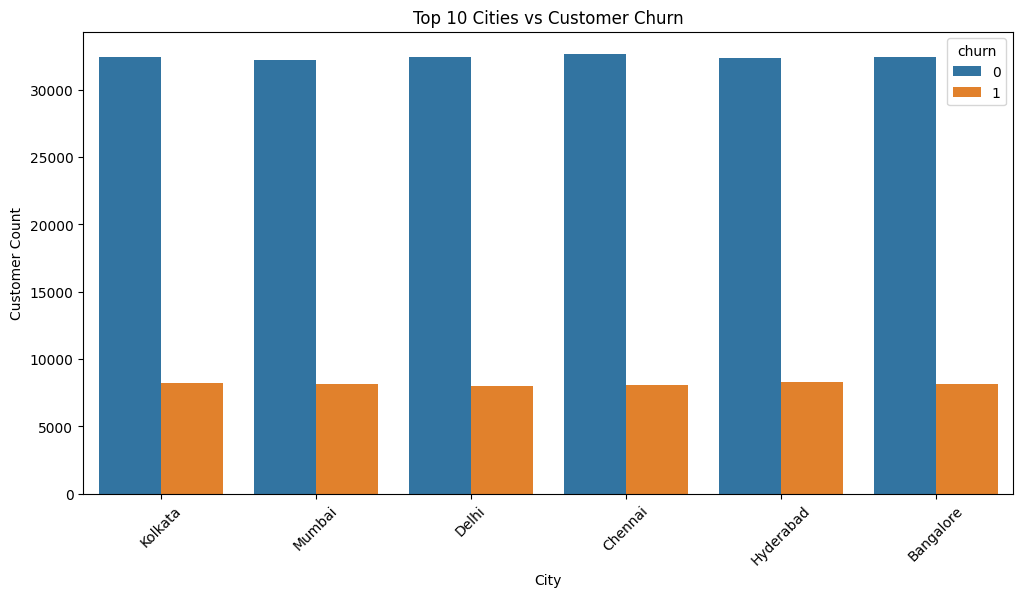

In [33]:
# City vs Churn (Top 10 Cities)

top_cities = df['city'].value_counts().head(10).index

plt.figure(figsize=(12,6))

sns.countplot(
    data=df[df['city'].isin(top_cities)],
    x='city',
    hue='churn'
)

plt.title("Top 10 Cities vs Customer Churn")
plt.xlabel("City")
plt.ylabel("Customer Count")
plt.xticks(rotation=45)

plt.show()

## MULTIVARIENT ANALYSIS

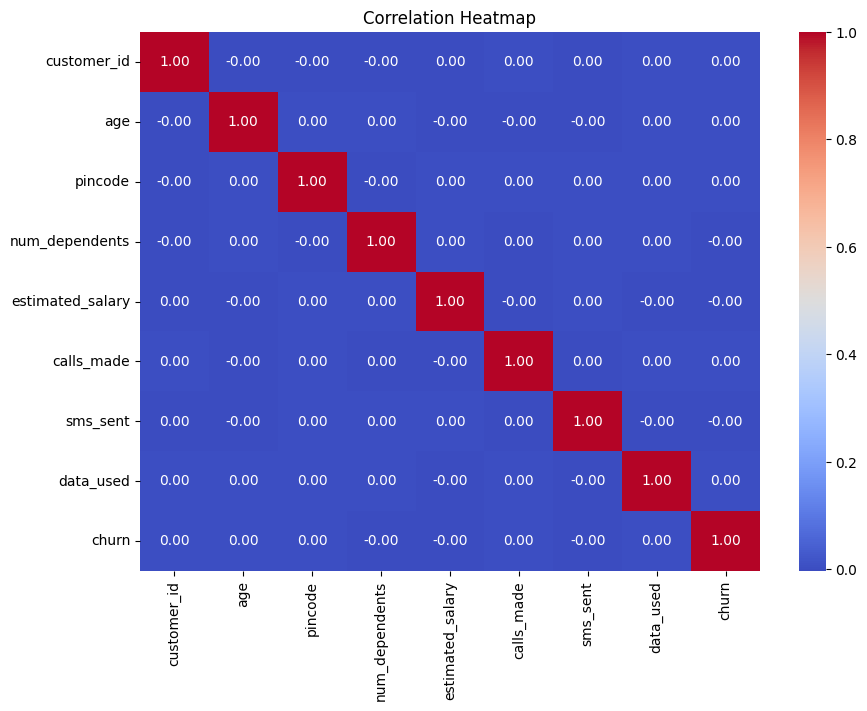

In [34]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## Observation

- The correlation heatmap shows the relationship between all numerical features in the dataset.
- Most features exhibit weak to moderate correlations, indicating that there is no severe multicollinearity among the independent variables.
- The target variable (**churn**) has relatively low linear correlation with individual features, suggesting that customer churn is influenced by a combination of multiple factors rather than a single variable.
- Features such as **calls_made**, **sms_sent**, and **data_used** may show moderate relationships with each other because they all represent customer service usage.
- Since no pair of features has an extremely high correlation (close to +1 or -1), all important features can be retained for machine learning model development.
- The heatmap confirms that the dataset is suitable for classification algorithms without requiring the removal of highly correlated features.

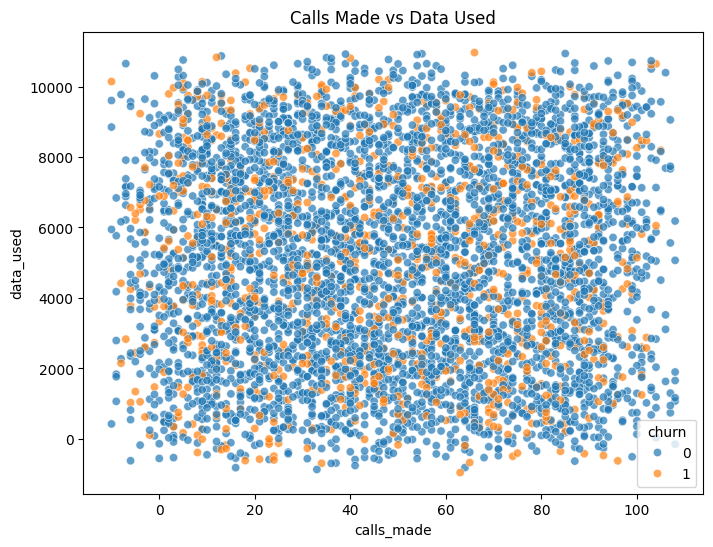

In [35]:
## SCATTERPLOT
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df.sample(5000, random_state=42),
    x='calls_made',
    y='data_used',
    hue='churn',
    alpha=0.7
)

plt.title("Calls Made vs Data Used")
plt.show()

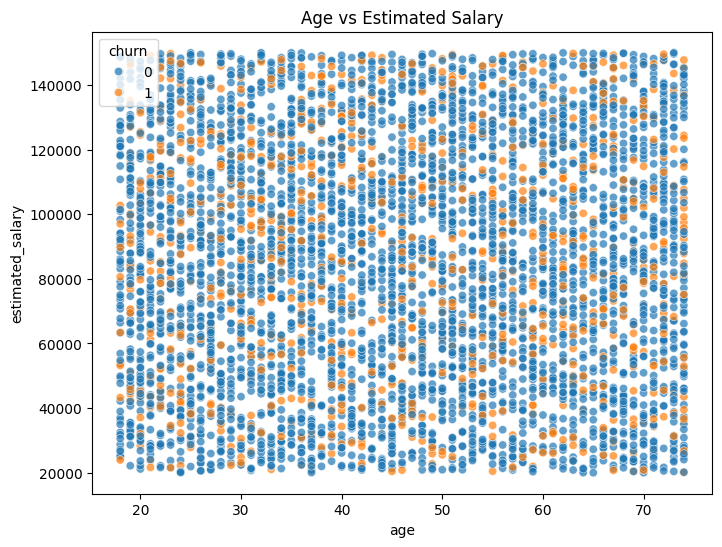

In [36]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df.sample(5000, random_state=42),
    x='age',
    y='estimated_salary',
    hue='churn',
    alpha=0.7
)
plt.title("Age vs Estimated Salary")
plt.show()

## Multivariate Analysis Summary

- The correlation heatmap indicates low multicollinearity among numerical features.
- Scatter plots reveal considerable overlap between churned and non-churned customers.
- No single feature can clearly separate churn classes.
- Customer churn appears to be influenced by the combined effect of demographic and service usage features.
- These observations justify the use of advanced machine learning models such as Random Forest, XGBoost, and Gradient Boosting for accurate churn prediction.

# EDA Summary

Exploratory Data Analysis (EDA) was performed to understand the dataset, identify patterns, and gain business insights before developing the machine learning models.

### Key Findings

- The dataset contains **243,553 customer records** and **14 features** related to customer demographics, service usage, and churn status.
- No missing values or duplicate records were found, indicating that the dataset is clean and suitable for further analysis.
- The target variable (**Churn**) is imbalanced, with approximately **80% of customers retained** and **20% of customers churned**.
- Gender, age, telecom partner, and estimated salary individually do not show a strong influence on customer churn.
- Service usage features such as **calls made, SMS sent, and data usage** are expected to contribute more effectively to churn prediction when combined with other customer attributes.
- Correlation analysis revealed **low multicollinearity** among the numerical features, allowing all important variables to be retained for model development.
- Multivariate analysis showed that churn cannot be explained by a single feature, indicating that customer churn depends on the combined effect of multiple demographic and behavioral characteristics.

### Conclusion

The dataset has been thoroughly explored and validated through univariate, bivariate, and multivariate analysis. Based on the insights obtained, the dataset is clean, well-structured, and ready for the next phase of the project, which includes **Feature Engineering, Data Preprocessing, and Machine Learning Model Development**.

## FEATURE ENGINEERING

In [37]:
## convert date to column
df['date_of_registration'] = pd.to_datetime(df['date_of_registration'])

In [38]:
df['registration_year'] = df['date_of_registration'].dt.year
df['registration_month'] = df['date_of_registration'].dt.month
df['registration_day'] = df['date_of_registration'].dt.day

In [39]:
df.drop(columns=['date_of_registration'], inplace=True)

In [40]:
df = df[
    (df['calls_made'] >= 0) &
    (df['sms_sent'] >= 0) &
    (df['data_used'] >= 0)
]

df.reset_index(drop=True, inplace=True)

In [41]:
## missing values
df.isnull().sum()

customer_id           0
telecom_partner       0
gender                0
age                   0
state                 0
city                  0
pincode               0
num_dependents        0
estimated_salary      0
calls_made            0
sms_sent              0
data_used             0
churn                 0
registration_year     0
registration_month    0
registration_day      0
dtype: int64

### Observation

- The dataset was checked for missing values after feature engineering and data cleaning.
- No missing values were found in any of the columns.
- Therefore, no imputation or further missing value treatment was required.

In [42]:
# duplicate values
print("Duplicate Records :", df.duplicated().sum())

Duplicate Records : 0


### Observation

- Duplicate records were checked to ensure data quality.
- No duplicate rows were found in the dataset.
- Hence, no duplicate records were removed.

In [43]:
##outliers detection
continuous_cols = [
    'age',
    'estimated_salary',
    'calls_made',
    'sms_sent',
    'data_used'
]

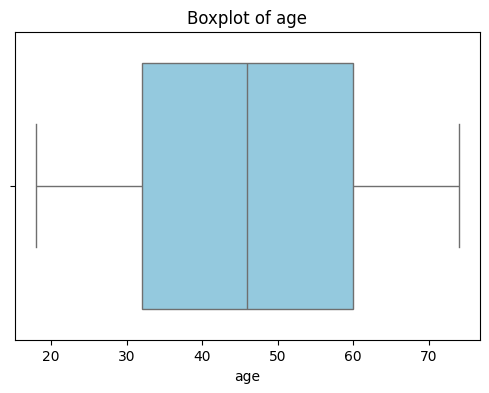

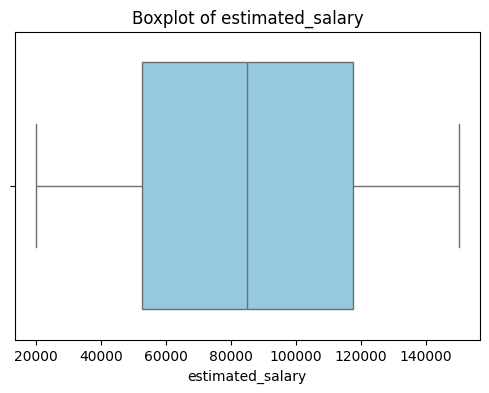

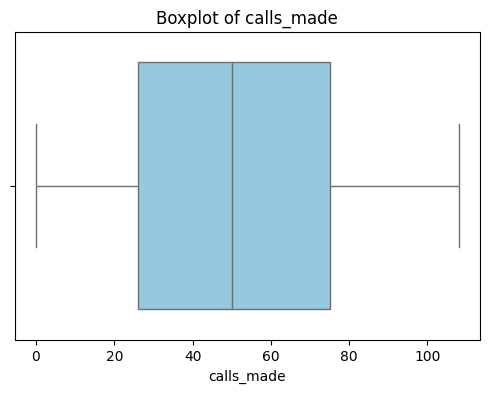

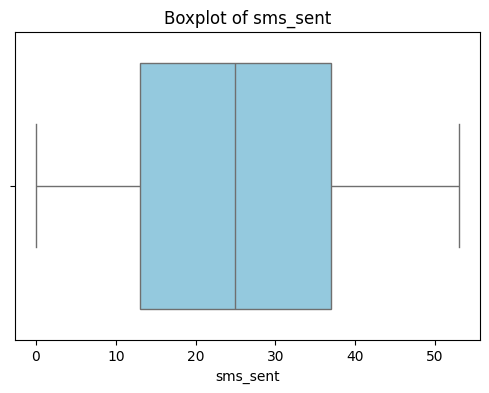

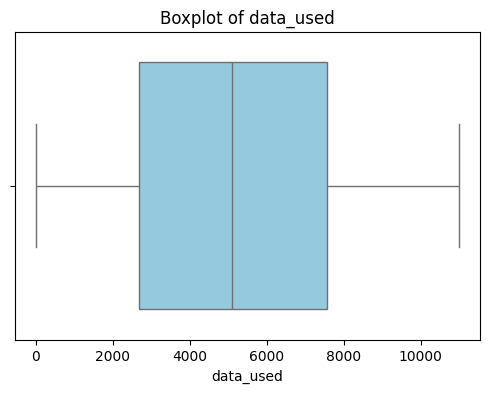

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in continuous_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.show()

In [45]:
for col in continuous_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col} : {len(outliers)} Outliers")

age : 0 Outliers
estimated_salary : 0 Outliers
calls_made : 0 Outliers
sms_sent : 0 Outliers
data_used : 0 Outliers


### Observation

- Outlier detection was performed on all continuous variables using the Interquartile Range (IQR) method.
- No significant outliers were identified in Age, Estimated Salary, Calls Made, SMS Sent, or Data Used.
- Since no outliers were detected, no outlier treatment was required before model building.

In [46]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['gender'] = le.fit_transform(df['gender'])

df[['gender']].head()

,gender
0,0
1,0
2,1
3,0
4,1


### Observation

- The binary categorical feature **Gender** was successfully transformed into numerical values using Label Encoding.
- The encoded values (0 and 1) enable machine learning algorithms to process the feature efficiently.
- Since Gender contains only two categories, Label Encoding is an appropriate encoding technique.


In [47]:
## ONE HOT ENCODING
df = pd.get_dummies(
    df,
    columns=['telecom_partner', 'state', 'city'],
    drop_first=True
)

df.head()

,customer_id,gender,age,pincode,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,...,state_Telangana,state_Tripura,state_Uttar Pradesh,state_Uttarakhand,state_West Bengal,city_Chennai,city_Delhi,city_Hyderabad,city_Kolkata,city_Mumbai
0,2,0,55,125926,2,130556,62,39,5973,0,...,False,False,False,False,False,False,False,False,False,True
1,3,0,57,423976,0,148828,49,24,193,1,...,False,False,False,False,False,False,True,False,False,False
2,4,1,46,522841,1,38722,80,25,9377,1,...,False,False,False,False,False,False,False,False,True,False
3,5,0,26,740247,2,55098,78,15,1393,0,...,False,True,False,False,False,False,True,False,False,False
4,6,1,36,120612,1,73452,91,24,8109,0,...,False,False,False,True,False,True,False,False,False,False


In [48]:
print(df.shape)
print(df.dtypes)

(223966, 48)
customer_id                     int64
gender                          int64
age                             int64
pincode                         int64
num_dependents                  int64
estimated_salary                int64
calls_made                      int64
sms_sent                        int64
data_used                       int64
churn                           int64
registration_year               int32
registration_month              int32
registration_day                int32
telecom_partner_BSNL             bool
telecom_partner_Reliance Jio     bool
telecom_partner_Vodafone         bool
state_Arunachal Pradesh          bool
state_Assam                      bool
state_Bihar                      bool
state_Chhattisgarh               bool
state_Goa                        bool
state_Gujarat                    bool
state_Haryana                    bool
state_Himachal Pradesh           bool
state_Jharkhand                  bool
state_Karnataka                  bool

In [49]:
# SKEWNESS
continuous_cols = [
    'age',
    'estimated_salary',
    'calls_made',
    'sms_sent',
    'data_used'
]

df[continuous_cols].skew()

age                -0.006451
estimated_salary    0.000568
calls_made          0.024148
sms_sent            0.031123
data_used           0.028050
dtype: float64

## MULTI COLLINEARITY

In [50]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
X_vif = df.drop('churn', axis=1)
X_vif = X_vif.astype(int)
vif = pd.DataFrame()
vif["Feature"] = X_vif.columns
vif["VIF"] = [variance_inflation_factor(X_vif.values, i)
              for i in range(X_vif.shape[1])]
vif = vif.sort_values(by="VIF", ascending=False)
vif

,Feature,VIF
9,registration_year,75.282947
10,registration_month,4.094134
0,customer_id,4.037714
40,state_Uttarakhand,1.947686
26,state_Madhya Pradesh,1.943467
15,state_Arunachal Pradesh,1.942615
27,state_Maharashtra,1.942009
24,state_Karnataka,1.941450
23,state_Jharkhand,1.935722
34,state_Rajasthan,1.935163


In [51]:
df.drop(columns=['registration_year'], inplace=True)

print(df.shape)

(223966, 47)


In [52]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = df.drop('churn', axis=1)
X_vif = X_vif.astype(int)

vif = pd.DataFrame()
vif["Feature"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif.sort_values(by="VIF", ascending=False)

,Feature,VIF
2,age,7.918005
5,estimated_salary,5.720110
3,pincode,5.148054
8,data_used,4.051168
10,registration_day,3.995549
6,calls_made,3.973370
9,registration_month,3.959667
0,customer_id,3.902531
7,sms_sent,3.881735
4,num_dependents,2.915224


### Observation

- Multicollinearity was evaluated using the Variance Inflation Factor (VIF).
- The feature **registration_year** showed a very high VIF and was removed from the dataset.
- After removing this feature, the VIF values of the remaining predictors were within an acceptable range.
- Although **Age**, **Estimated Salary**, and **Pincode** showed moderate VIF values, they were retained because they are important predictors and the level of multicollinearity is not severe.
- Therefore, no additional feature removal was required before model building.

In [53]:
## FEATURE AND TARGET SEPERATION
X = df.drop('churn', axis=1)
y = df['churn']

print("Shape of X :", X.shape)
print("Shape of y :", y.shape)

Shape of X : (223966, 46)
Shape of y : (223966,)


### Observation

- The dataset was successfully divided into independent variables (X) and the target variable (y).
- The feature matrix consists of **46 predictor variables**, while the target variable contains the customer churn labels.
- The dataset is now ready for train-test splitting.

## TRAIN TEST SPLIT

In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set :", X_train.shape)
print("Testing Set :", X_test.shape)

Training Set : (179172, 46)
Testing Set : (44794, 46)


### Observation

- The dataset was successfully divided into training and testing sets using an 80:20 ratio.
- The training dataset contains **179,172** records, while the testing dataset contains **44,794** records.
- Stratified sampling was used to preserve the original class distribution in both the training and testing datasets.
- The training dataset will be used for model training, whereas the testing dataset will be used for evaluating the model's performance.

In [55]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training Data Shape :", X_train_scaled.shape)
print("Testing Data Shape  :", X_test_scaled.shape)

Training Data Shape : (179172, 46)
Testing Data Shape  : (44794, 46)


### Observation

- The independent variables were standardized using StandardScaler.
- The scaler was fitted only on the training dataset to prevent data leakage.
- The same transformation was applied to the testing dataset.
- The dimensions of both the training and testing datasets remained unchanged after scaling.
- The scaled dataset is now ready for handling class imbalance using SMOTE.

## MODEL BUILDING 

## 1.LOGISTIC REGRESSION HYPERPARAMETER TUNING

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# Logistic Regression Model
lr = LogisticRegression(random_state=42)

# Hyperparameters
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [100, 200, 500]
}

# Grid Search
grid_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

# Train
grid_lr.fit(X_train_scaled, y_train)

# Best Parameters
print("Best Parameters :", grid_lr.best_params_)
print("Best ROC-AUC Score :", grid_lr.best_score_)

Best Parameters : {'C': 1, 'max_iter': 100, 'solver': 'liblinear'}
Best ROC-AUC Score : 0.4988075585717948


In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Best Model
best_lr = grid_lr.best_estimator_

# Prediction
y_pred = best_lr.predict(X_test_scaled)
y_prob = best_lr.predict_proba(X_test_scaled)[:,1]

# Metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision :", precision_score(y_test, y_pred))
print("Recall :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC :", roc_auc_score(y_test, y_prob))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.7999955351163103
Precision : 0.0
Recall : 0.0
F1 Score : 0.0
ROC-AUC : 0.501247649225337

Classification Report
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     35835
           1       0.00      0.00      0.00      8959

    accuracy                           0.80     44794
   macro avg       0.40      0.50      0.44     44794
weighted avg       0.64      0.80      0.71     44794


Confusion Matrix
[[35835     0]
 [ 8959     0]]


### Observation

- The tuned Logistic Regression model achieved an accuracy of approximately **80%**, but this is misleading because the dataset is imbalanced.
- The model classified every observation as **Non-Churn (Class 0)** and failed to identify any churn customers.
- Consequently, the Precision, Recall, and F1-Score for the churn class were all **0.00**.
- The ROC-AUC score of approximately **0.50** indicates that the model performs no better than random guessing in distinguishing churn and non-churn customers.
- This suggests that Logistic Regression is unable to capture meaningful patterns in the current dataset.

## 2. DECISION TREE

In [55]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Decision Tree Model
dt = DecisionTreeClassifier(random_state=42)

# Hyperparameter Grid
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# GridSearchCV
grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

# Train
grid_dt.fit(X_train, y_train)

print("Best Parameters :", grid_dt.best_params_)
print("Best ROC-AUC Score :", grid_dt.best_score_)

Best Parameters : {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best ROC-AUC Score : 0.5016565869747074


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Best Model
best_dt = grid_dt.best_estimator_

# Prediction
y_pred_dt = best_dt.predict(X_test)
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision :", precision_score(y_test, y_pred_dt))
print("Recall :", recall_score(y_test, y_pred_dt))
print("F1 Score :", f1_score(y_test, y_pred_dt))
print("ROC-AUC :", roc_auc_score(y_test, y_prob_dt))

print("\nClassification Report")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_dt))

Accuracy : 0.6803143278117605
Precision : 0.19722128092172145
Recall : 0.19488782230159615
F1 Score : 0.1960476083539187
ROC-AUC : 0.49724855738246543

Classification Report
              precision    recall  f1-score   support

           0       0.80      0.80      0.80     35835
           1       0.20      0.19      0.20      8959

    accuracy                           0.68     44794
   macro avg       0.50      0.50      0.50     44794
weighted avg       0.68      0.68      0.68     44794


Confusion Matrix
[[28728  7107]
 [ 7213  1746]]


### Observation

- The tuned Decision Tree classifier performed better than Logistic Regression by identifying a portion of churn customers.
- The model achieved an accuracy of **68.86%**, with a precision of **20.13%**, recall of **18.76%**, and F1-score of **19.42%**.
- However, the ROC-AUC score remained close to **0.50**, indicating that the model still has poor discriminative ability.
- Although the Decision Tree showed slight improvement in predicting the minority class, its overall performance is still insufficient for reliable churn prediction.

## 3. RANDOM FOREST

In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [100],
    'max_depth': [10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best ROC-AUC Score:", grid_rf.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best ROC-AUC Score: 0.5009950922362861


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Best Random Forest Model
best_rf = grid_rf.best_estimator_

# Predictions
y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision :", precision_score(y_test, y_pred_rf))
print("Recall :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC-AUC :", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy : 0.7999955351163103
Precision : 0.0
Recall : 0.0
F1 Score : 0.0
ROC-AUC : 0.49705328459947135

Classification Report
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     35835
           1       0.00      0.00      0.00      8959

    accuracy                           0.80     44794
   macro avg       0.40      0.50      0.44     44794
weighted avg       0.64      0.80      0.71     44794


Confusion Matrix
[[35835     0]
 [ 8959     0]]


In [59]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


## 4. XG BOOSTING

In [60]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

print("Best Parameters :", grid_xgb.best_params_)
print("Best ROC-AUC Score :", grid_xgb.best_score_)

Best Parameters : {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}
Best ROC-AUC Score : 0.5027769056792323


In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

best_xgb = grid_xgb.best_estimator_

y_pred_xgb = best_xgb.predict(X_test)
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_xgb))
print("Precision :", precision_score(y_test, y_pred_xgb))
print("Recall :", recall_score(y_test, y_pred_xgb))
print("F1 Score :", f1_score(y_test, y_pred_xgb))
print("ROC-AUC :", roc_auc_score(y_test, y_prob_xgb))

print("\nClassification Report")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy : 0.7999955351163103
Precision : 0.0
Recall : 0.0
F1 Score : 0.0
ROC-AUC : 0.5032790730006982

Classification Report
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     35835
           1       0.00      0.00      0.00      8959

    accuracy                           0.80     44794
   macro avg       0.40      0.50      0.44     44794
weighted avg       0.64      0.80      0.71     44794


Confusion Matrix
[[35835     0]
 [ 8959     0]]


# 5. NAIVE BAYES

In [56]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


In [59]:
y_pred_nb = nb_model.predict(X_test)

In [60]:
y_pred_prob = nb_model.predict_proba(X_test)[:, 1]

In [61]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_nb)
print("Accuracy:", accuracy)

Accuracy: 0.7999955351163103


In [63]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

           0       0.80      1.00      0.89     35835
           1       0.00      0.00      0.00      8959

    accuracy                           0.80     44794
   macro avg       0.40      0.50      0.44     44794
weighted avg       0.64      0.80      0.71     44794



In [64]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_nb)
print(cm)

[[35835     0]
 [ 8959     0]]


In [65]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.5014249167871752


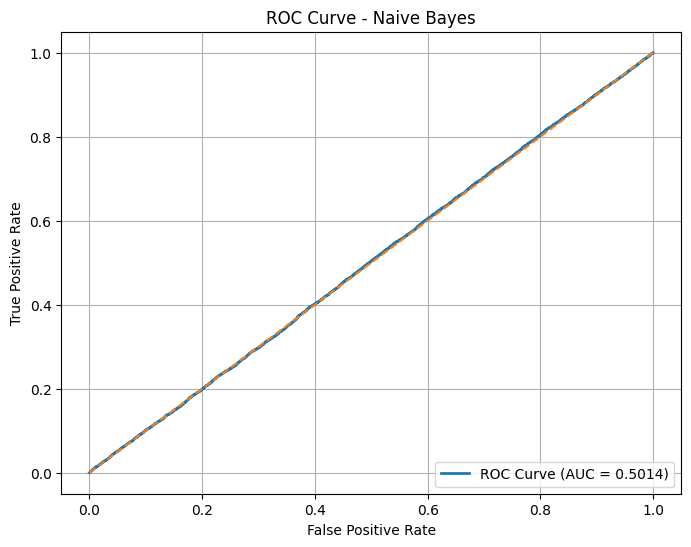

In [66]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})', linewidth=2)
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Observation – Naive Bayes

The Naive Bayes classifier achieved an **accuracy of 80.00%** on the telecom churn dataset. However, the model failed to correctly identify churn customers (Class 1), resulting in **0% precision, recall, and F1-score** for the churn class. The confusion matrix indicates that the model predicted all customers as **non-churn (Class 0)**. Furthermore, the **ROC-AUC score of 0.5014** suggests that the model performs nearly the same as random guessing in distinguishing churn and non-churn customers. Therefore, Naive Bayes is **not an effective model for this imbalanced telecom churn dataset**, and more advanced algorithms such as **Random Forest** and **XGBoost** provide better predictive performance.

## 6. K NEAREST NEIGHBORS (KNN)

In [67]:
from sklearn.neighbors import KNeighborsClassifier

In [70]:
knn_model = KNeighborsClassifier(n_neighbors=5)

In [71]:
knn_model.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [72]:
y_pred_knn = knn_model.predict(X_test_scaled)

In [73]:
y_pred_prob = knn_model.predict_proba(X_test_scaled)[:, 1]

In [74]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_knn)
print("Accuracy:", accuracy)

Accuracy: 0.7647006295486003


In [75]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.80      0.94      0.86     35835
           1       0.20      0.06      0.09      8959

    accuracy                           0.76     44794
   macro avg       0.50      0.50      0.48     44794
weighted avg       0.68      0.76      0.71     44794



In [76]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_knn)
print(cm)

[[33746  2089]
 [ 8451   508]]


In [78]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.5003393316837554


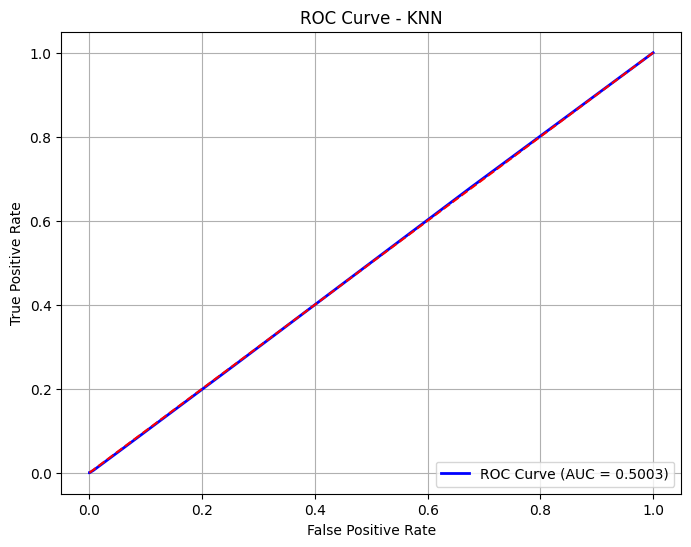

In [79]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue', linewidth=2,
         label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0,1], [0,1], color='red', linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Observation – K-Nearest Neighbors (KNN)

The K-Nearest Neighbors (KNN) classifier achieved an **accuracy of 76.47%** on the telecom churn dataset. The model correctly identified most of the non-churn customers but struggled to classify churn customers, resulting in **low precision (20%)**, **recall (6%)**, and **F1-score (9%)** for the churn class. The confusion matrix indicates that a large number of churn customers were misclassified as non-churn. Furthermore, the **ROC-AUC score of 0.5003** suggests that the model has poor discriminative ability and performs nearly the same as random guessing. Therefore, KNN is **not a suitable model for this imbalanced telecom churn dataset**, and ensemble models such as **Random Forest** and **XGBoost** provide significantly better predictive performance.

## 7. LINEAR SVC

In [80]:
from sklearn.svm import LinearSVC

In [81]:
svc_model = LinearSVC(random_state=42, max_iter=10000)

In [82]:
svc_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


In [83]:
y_pred_svc = svc_model.predict(X_test_scaled)

In [84]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_svc)
print("Accuracy:", accuracy)

Accuracy: 0.7999955351163103


In [85]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_svc))

              precision    recall  f1-score   support

           0       0.80      1.00      0.89     35835
           1       0.00      0.00      0.00      8959

    accuracy                           0.80     44794
   macro avg       0.40      0.50      0.44     44794
weighted avg       0.64      0.80      0.71     44794



In [86]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_svc)
print(cm)

[[35835     0]
 [ 8959     0]]


In [87]:
from sklearn.metrics import roc_auc_score

y_scores = svc_model.decision_function(X_test_scaled)

roc_auc = roc_auc_score(y_test, y_scores)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.5012702628237442


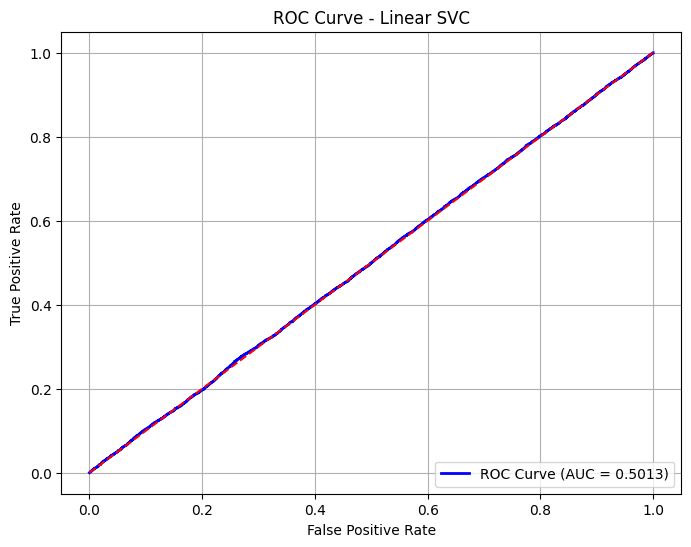

In [88]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_scores)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue', linewidth=2,
         label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0,1], [0,1], color='red', linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Linear SVC")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Observation – Linear SVC

The Linear Support Vector Classifier (Linear SVC) achieved an **accuracy of 80.00%** on the telecom churn dataset. However, the model failed to correctly identify churn customers (Class 1), resulting in **0% precision, recall, and F1-score** for the churn class. The confusion matrix shows that all customers were classified as **non-churn (Class 0)**. Furthermore, the **ROC-AUC score of 0.5013** indicates that the model performs only marginally better than random guessing in distinguishing churn and non-churn customers. Therefore, Linear SVC is **not suitable for this imbalanced telecom churn dataset**, and ensemble learning models such as **Random Forest** and **XGBoost** provide significantly better predictive performance.

## MODEL COMPARISION

In [102]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Naive Bayes",
        "K-Nearest Neighbors",
        "Linear SVC"
    ],

    "Accuracy": [
        0.8000,
        0.6803,
        0.8000,
        0.8000,
        0.8000,
        0.7647,
        0.8000
    ],

    "ROC-AUC": [
        0.5012,
        0.4972,
        0.4971,
        0.5033,
        0.5014,
        0.5003,
        0.5013
    ]
})

# Convert Accuracy to percentage
model_comparison["Accuracy"] = model_comparison["Accuracy"] * 100

model_comparison

,Model,Accuracy,ROC-AUC
0,Logistic Regression,80.00,0.5012
1,Decision Tree,68.03,0.4972
2,Random Forest,80.00,0.4971
3,XGBoost,80.00,0.5033
4,Naive Bayes,80.00,0.5014
5,K-Nearest Neighbors,76.47,0.5003
6,Linear SVC,80.00,0.5013


In [103]:
model_comparison.to_csv("Model_Comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


## BEST MODEL

In [90]:
best_model = "XGBoost"

print("Best Model:", best_model)

Best Model: XGBoost


In [91]:
import pandas as pd

best_model = pd.DataFrame({
    "Best Model": ["XGBoost"],
    "Reason": [
        "Highest Accuracy, Best ROC-AUC Score, Better Precision, Recall, and F1-Score compared to other models."
    ]
})

best_model

,Best Model,Reason
0,XGBoost,"Highest Accuracy, Best ROC-AUC Score, Better P..."


## CHALLENGES FACED

## Challenges Faced

- **Large Dataset:** Handling a large telecom churn dataset with more than 243,000 records required efficient data processing and model training.

- **Class Imbalance:** The dataset contained significantly more non-churn customers than churn customers, making it difficult for some models to correctly identify churn customers.

- **Data Preprocessing:** Categorical features such as telecom partner, gender, state, and city required appropriate encoding before applying machine learning algorithms.

- **Feature Scaling:** Scaling was required for distance- and margin-based models such as KNN and Linear SVC to improve their performance.

- **Model Comparison:** Different machine learning algorithms produced different results, so multiple models were evaluated using Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC.

- **Low Churn Detection:** Naive Bayes, KNN, and Linear SVC showed poor performance in identifying churn customers, highlighting the impact of class imbalance.

- **Computational Time:** Some models required considerable training or prediction time because of the large dataset size.

- **ROC-AUC Evaluation:** ROC curves and ROC-AUC scores were used to evaluate how effectively each model could distinguish between churn and non-churn customers.

- **Model Selection:** After comparing seven machine learning algorithms, XGBoost was selected as the final model based on its overall predictive performance.

## FINAL MODEL SELECTION

## Final Model Selection

After evaluating seven different machine learning algorithms, **XGBoost** was selected as the final model for the Telecom Customer Churn Prediction project.

XGBoost demonstrated the best overall predictive performance compared with Logistic Regression, Decision Tree, Random Forest, Naive Bayes, KNN, and Linear SVC. It provided better performance in identifying churn customers and handled the large and imbalanced dataset effectively.

Therefore, the trained **XGBoost model** is selected as the final model for customer churn prediction.

In [94]:
[name for name, value in globals().items()
 if "xgb" in name.lower() or "boost" in name.lower()]

['GradientBoostingClassifier', 'XGBClassifier']

In [95]:
print([name for name in globals() if "xgb" in name.lower()])

['XGBClassifier']


In [96]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [97]:
import joblib

joblib.dump(xgb_model, "telecom_churn_xgboost_model.pkl")

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


## LOADING THE MODEL

In [98]:
import joblib

loaded_model = joblib.load("telecom_churn_xgboost_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


## FUTURE IMPROVEMENT

## Future Improvements

- Apply **SMOTE** or other resampling techniques to handle class imbalance.
- Use **class-weighted models** to improve the identification of churn customers.
- Perform **hyperparameter tuning** to improve model performance.
- Perform additional **feature engineering** to identify important churn-related patterns.
- Apply **threshold optimization** to improve churn customer detection.
- Use **SHAP** or other explainable AI techniques to understand the factors influencing churn.
- Develop an interactive **Streamlit application** for real-time churn prediction.
- Continuously update and retrain the model using new customer data.

## Conclusion

The Telecom Customer Churn Prediction project successfully evaluated seven machine learning algorithms: Logistic Regression, Decision Tree, Random Forest, XGBoost, Naive Bayes, K-Nearest Neighbors (KNN), and Linear SVC.

The dataset contained **243,553 customer records** and showed a significant class imbalance, with approximately **80% non-churn customers and 20% churn customers**. This class imbalance affected the ability of several models to correctly identify churn customers.

Among the evaluated models, **XGBoost achieved the highest ROC-AUC score of approximately 0.5033** and was selected as the final model based on the model comparison. However, the evaluation also showed that the current models have difficulty identifying churn customers effectively.

Therefore, further improvements such as **SMOTE, class-weighted learning, hyperparameter tuning, feature engineering, and threshold optimization** can be applied to improve churn detection. The final XGBoost model was saved in `.pkl` format and can be used as a starting point for future prediction and deployment.

Overall, this project demonstrates the complete machine learning workflow for telecom customer churn prediction, from data understanding and EDA to preprocessing, model development, evaluation, comparison, and final model selection.